# Hourly energy demand generation and weather




Project link : https://www.kaggle.com/nicholasjhana/energy-consumption-generation-prices-and-weather
This dataset contains 4 years of electrical consumption, generation, pricing, and weather data for Spain for 4 years.
There are 2 files 
1. energy_dataset : Time series generation of electricity in MW through various sources like Biomass, coal, solar etc
2. weather_features : Time series data of cities in spain and their weather data like humidity, temperature, pressure etc


Objective: Predict Spain's total energy demand
Data type: Time series data
Data shape: 
energy forecast : 35000 x 29 columns
weather features : 178k x 17 columns

Columns understanding (from kaggle )


Inpiration, from Kaggle:

Visualize the load and marginal supply curves.
What weather measurements, and cities influence most the electrical demand, prices, generation capacity?
Can we forecast 24 hours in advance better than the TSO?
Can we predict electrical price by time of day better than TSO?
Forecast intraday price or electrical demand hour-by-hour.
What is the next generation source to be activated on the load curve?

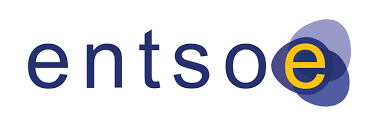



Official steps:
1. Pick a large real-world dataset from Kaggle (see the "Recommended Datasets" section below) and download it using opendatasets. Your training set should contain at least 50,000 rows and 5 columns of data.

2. Read the dataset description, understand the problem statement and describe the modeling objective clearly. You can also browse through existing notebooks created by others for inspiration.

3. Perform exploratory data analysis, gather insights about the data, perform feature engineering, create a training-validation split, and prepare the data for modeling.

4. Train & evaluate different machine learning models, tune hyperparameters and reduce overfitting to improve the model.

5. Report the final performance of your best model(s), show sample predictions, and save model weights. Summarize your work, share links to references, and suggest ideas for future work.

6. Publish your Jupyter notebook to Jovian, make a submission below and share your project with the community. Optionally, you may also write a blog post and contribute to the Jovian official blog.

Evaluation Criteria
Your submission must satisfy the following criteria:

1. Training set should contain at least 50,000 rows of data and 5 columns
2. Notebook must include all the steps listed in the project guidelines above
3. Notebook must be executed end-to-end with error-free outputs for all cells
4. You must train at least 2 different types of machine learning models
5. You must tune at least 2 different hyperparameters for your chosen model
6. Your model's performance on the validation set must be reasonably good
7. Your project must be documented extensively using markdown cells
8. Notebook must include references to relevant notebooks/tutorials/documentation sites
9. Your notebook must not be plagiarized (i.e., directly copied) from another project

1. Load dataset using opendatasets from Kaggle
2. analyze files energy_dataset and weather_features and try to figure out a way to combine features. Find target and input columns.
3. EDA on the data (find correlations, graphs, missing data, inf, NANs, means, outliers etc)
4. Feature engineering (create new columns from Date, use uncertianity in a different way. Target column: Price_day or price_actual or total_load_forecast, total_load_actual)
5. Imputation on numerical cols, No categorical columns so no one hot encoding required.
6. Train-val-test split (70:10:20)
7. Use Linear regression (fit ax1+bx2+cx3+... = y), random forest, Gradient boosting, Light GBM.
8. Tune hyperparameters of random forest, GBM, light GBM.
9. Find out accuracies and figure out the best model
10. Sample predictions on some small data, features importances(weights)
11. Summarize the findings 


# Downloading the data


In [2]:
import os
import opendatasets as od
import pandas as pd
import numpy as np
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 120)
from dateutil.parser import parse
from dateutil.tz import tzoffset

In [3]:
od.download('https://www.kaggle.com/nicholasjhana/energy-consumption-generation-prices-and-weather')

In [4]:
os.listdir('energy-consumption-generation-prices-and-weather/')

['energy_dataset.csv', 'weather_features.csv']

In [5]:
energy_dataset = pd.read_csv('energy-consumption-generation-prices-and-weather/energy_dataset.csv',skipinitialspace=True)
weather_features = pd.read_csv('energy-consumption-generation-prices-and-weather/weather_features.csv',skipinitialspace=True
)

In [6]:
energy_dataset.rename(columns={'time' : 'datetime'}, inplace=True)
weather_features.rename(columns={'dt_iso' : 'datetime'}, inplace=True)

In [7]:
energy_dataset

,datetime,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage aggregated,generation hydro pumped storage consumption,generation hydro run-of-river and poundage,generation hydro water reservoir,generation marine,generation nuclear,generation other,generation other renewable,generation solar,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind offshore eday ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual
0,2015-01-01 00:00:00+01:00,447.0,329.0,0.0,4844.0,4821.0,162.0,0.0,0.0,0.0,NaN,863.0,1051.0,1899.0,0.0,7096.0,43.0,73.0,49.0,196.0,0.0,6378.0,17.0,NaN,6436.0,26118.0,25385.0,50.10,65.41
1,2015-01-01 01:00:00+01:00,449.0,328.0,0.0,5196.0,4755.0,158.0,0.0,0.0,0.0,NaN,920.0,1009.0,1658.0,0.0,7096.0,43.0,71.0,50.0,195.0,0.0,5890.0,16.0,NaN,5856.0,24934.0,24382.0,48.10,64.92
2,2015-01-01 02:00:00+01:00,448.0,323.0,0.0,4857.0,4581.0,157.0,0.0,0.0,0.0,NaN,1164.0,973.0,1371.0,0.0,7099.0,43.0,73.0,50.0,196.0,0.0,5461.0,8.0,NaN,5454.0,23515.0,22734.0,47.33,64.48
3,2015-01-01 03:00:00+01:00,438.0,254.0,0.0,4314.0,4131.0,160.0,0.0,0.0,0.0,NaN,1503.0,949.0,779.0,0.0,7098.0,43.0,75.0,50.0,191.0,0.0,5238.0,2.0,NaN,5151.0,22642.0,21286.0,42.27,59.32
4,2015-01-01 04:00:00+01:00,428.0,187.0,0.0,4130.0,3840.0,156.0,0.0,0.0,0.0,NaN,1826.0,953.0,720.0,0.0,7097.0,43.0,74.0,42.0,189.0,0.0,4935.0,9.0,NaN,4861.0,21785.0,20264.0,38.41,56.04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35059,2018-12-31 19:00:00+01:00,297.0,0.0,0.0,7634.0,2628.0,178.0,0.0,0.0,0.0,NaN,1.0,1135.0,4836.0,0.0,6073.0,63.0,95.0,85.0,277.0,0.0,3113.0,96.0,NaN,3253.0,30619.0,30653.0,68.85,77.02
35060,2018-12-31 20:00:00+01:00,296.0,0.0,0.0,7241.0,2566.0,174.0,0.0,0.0,0.0,NaN,1.0,1172.0,3931.0,0.0,6074.0,62.0,95.0,33.0,280.0,0.0,3288.0,51.0,NaN,3353.0,29932.0,29735.0,68.40,76.16
35061,2018-12-31 21:00:00+01:00,292.0,0.0,0.0,7025.0,2422.0,168.0,0.0,0.0,0.0,NaN,50.0,1148.0,2831.0,0.0,6076.0,61.0,94.0,31.0,286.0,0.0,3503.0,36.0,NaN,3404.0,27903.0,28071.0,66.88,74.30
35062,2018-12-31 22:00:00+01:00,293.0,0.0,0.0,6562.0,2293.0,163.0,0.0,0.0,0.0,NaN,108.0,1128.0,2068.0,0.0,6075.0,61.0,93.0,31.0,287.0,0.0,3586.0,29.0,NaN,3273.0,25450.0,25801.0,63.93,69.89


In [8]:
weather_features

,datetime,city_name,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main,weather_description,weather_icon
0,2015-01-01 00:00:00+01:00,Valencia,270.475,270.475,270.475,1001,77,1,62,0.0,0.0,0.0,0,800,clear,sky is clear,01n
1,2015-01-01 01:00:00+01:00,Valencia,270.475,270.475,270.475,1001,77,1,62,0.0,0.0,0.0,0,800,clear,sky is clear,01n
2,2015-01-01 02:00:00+01:00,Valencia,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,0,800,clear,sky is clear,01n
3,2015-01-01 03:00:00+01:00,Valencia,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,0,800,clear,sky is clear,01n
4,2015-01-01 04:00:00+01:00,Valencia,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,0,800,clear,sky is clear,01n
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
178391,2018-12-31 19:00:00+01:00,Seville,287.760,287.150,288.150,1028,54,3,30,0.0,0.0,0.0,0,800,clear,sky is clear,01n
178392,2018-12-31 20:00:00+01:00,Seville,285.760,285.150,286.150,1029,62,3,30,0.0,0.0,0.0,0,800,clear,sky is clear,01n
178393,2018-12-31 21:00:00+01:00,Seville,285.150,285.150,285.150,1028,58,4,50,0.0,0.0,0.0,0,800,clear,sky is clear,01n
178394,2018-12-31 22:00:00+01:00,Seville,284.150,284.150,284.150,1029,57,4,60,0.0,0.0,0.0,0,800,clear,sky is clear,01n


# Preprocessing and feature engineering

In [10]:
energy_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 29 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   datetime                                     35064 non-null  object 
 1   generation biomass                           35045 non-null  float64
 2   generation fossil brown coal/lignite         35046 non-null  float64
 3   generation fossil coal-derived gas           35046 non-null  float64
 4   generation fossil gas                        35046 non-null  float64
 5   generation fossil hard coal                  35046 non-null  float64
 6   generation fossil oil                        35045 non-null  float64
 7   generation fossil oil shale                  35046 non-null  float64
 8   generation fossil peat                       35046 non-null  float64
 9   generation geothermal                        35046 non-null  float64
 10

In [11]:
weather_features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178396 entries, 0 to 178395
Data columns (total 17 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   datetime             178396 non-null  object 
 1   city_name            178396 non-null  object 
 2   temp                 178396 non-null  float64
 3   temp_min             178396 non-null  float64
 4   temp_max             178396 non-null  float64
 5   pressure             178396 non-null  int64  
 6   humidity             178396 non-null  int64  
 7   wind_speed           178396 non-null  int64  
 8   wind_deg             178396 non-null  int64  
 9   rain_1h              178396 non-null  float64
 10  rain_3h              178396 non-null  float64
 11  snow_3h              178396 non-null  float64
 12  clouds_all           178396 non-null  int64  
 13  weather_id           178396 non-null  int64  
 14  weather_main         178396 non-null  object 
 15  weather_descripti

In [12]:
energy_dataset.datetime.min(), energy_dataset.datetime.max(), weather_features.datetime.min(), weather_features.datetime.max()

('2015-01-01 00:00:00+01:00',
 '2018-12-31 23:00:00+01:00',
 '2015-01-01 00:00:00+01:00',
 '2018-12-31 23:00:00+01:00')

In [13]:
weather_features.datetime.nunique(), energy_dataset.datetime.nunique(), weather_features.datetime.shape

(35064, 35064, (178396,))

In [14]:
weather_features.city_name.unique()

array(['Valencia', 'Madrid', 'Bilbao', 'Barcelona', 'Seville'],
      dtype=object)

In [15]:
weather_features[weather_features['datetime'] == '2015-01-01 02:00:00+01:00']
# 5 rows for each city
# so 35064*5 = 175320

,datetime,city_name,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main,weather_description,weather_icon
2,2015-01-01 02:00:00+01:00,Valencia,269.686000,269.686000,269.686000,1002,78,0,23,0.0,0.0,0.0,0,800,clear,sky is clear,01n
35147,2015-01-01 02:00:00+01:00,Madrid,266.186000,266.186000,266.186000,971,64,1,273,0.0,0.0,0.0,0,800,clear,sky is clear,01n
71414,2015-01-01 02:00:00+01:00,Bilbao,269.251688,269.251688,269.251688,1036,97,1,224,0.0,0.0,0.0,0,800,clear,sky is clear,01
107365,2015-01-01 02:00:00+01:00,Barcelona,281.286000,281.286000,281.286000,1036,100,7,48,0.0,0.0,0.0,0,800,clear,sky is clear,01n
142841,2015-01-01 02:00:00+01:00,Seville,274.086000,274.086000,274.086000,1039,71,3,27,0.0,0.0,0.0,0,800,clear,sky is clear,01n


In [16]:
#So there are duplicate rows in the data : 178396 - 175320 = 3076 duplicate rows


In [17]:

#Let's extract date level columns from datetime

def split_date(df):
    df['Date'] = pd.to_datetime(df['date'])
    df['Year'] = df.Date.dt.year
    df['Month'] = df.Date.dt.month
    df['Day'] = df.Date.dt.day
    df['WeekOfYear'] = df.Date.dt.isocalendar().week
    df['dayofweek'] = df.Date.dt.dayofweek


In [18]:
#city related modifications
weather_val = weather_features[weather_features['city_name'] == 'Valencia'].drop_duplicates(subset='datetime')
weather_bil = weather_features[weather_features['city_name'] == 'Bilbao'].drop_duplicates(subset='datetime')
weather_bar = weather_features[weather_features['city_name'] == 'Barcelona'].drop_duplicates(subset='datetime')
weather_sev = weather_features[weather_features['city_name'] == 'Seville'].drop_duplicates(subset='datetime')
weather_mad = weather_features[weather_features['city_name'] == 'Madrid'].drop_duplicates(subset='datetime')

weather_val.shape, weather_mad.shape, weather_bil.shape, weather_bar.shape, weather_sev.shape

((35064, 17), (35064, 17), (35064, 17), (35064, 17), (35064, 17))

In [19]:
print(weather_bar.datetime.min(), energy_dataset.datetime.min(), weather_bar.datetime.max(), energy_dataset.datetime.max())

print(weather_bil.datetime.min(), energy_dataset.datetime.min(), weather_bil.datetime.max(), energy_dataset.datetime.max())

print(weather_mad.datetime.min(), energy_dataset.datetime.min(), weather_mad.datetime.max(), energy_dataset.datetime.max())

print(weather_sev.datetime.min(), energy_dataset.datetime.min(), weather_sev.datetime.max(), energy_dataset.datetime.max())

print(weather_val.datetime.min(), energy_dataset.datetime.min(), weather_val.datetime.max(), energy_dataset.datetime.max())

2015-01-01 00:00:00+01:00 2015-01-01 00:00:00+01:00 2018-12-31 23:00:00+01:00 2018-12-31 23:00:00+01:00
2015-01-01 00:00:00+01:00 2015-01-01 00:00:00+01:00 2018-12-31 23:00:00+01:00 2018-12-31 23:00:00+01:00
2015-01-01 00:00:00+01:00 2015-01-01 00:00:00+01:00 2018-12-31 23:00:00+01:00 2018-12-31 23:00:00+01:00
2015-01-01 00:00:00+01:00 2015-01-01 00:00:00+01:00 2018-12-31 23:00:00+01:00 2018-12-31 23:00:00+01:00
2015-01-01 00:00:00+01:00 2015-01-01 00:00:00+01:00 2018-12-31 23:00:00+01:00 2018-12-31 23:00:00+01:00


Both these have the same time dimensions and start and end hours. Weather has multiple rows of the same hours as it has the data for multiple cities recorded. So we can join these two tables Weather left join energy

In [20]:
# But first, let's find the null values

# NA or Null values


In [21]:
weather_features.isna().sum()

datetime               0
city_name              0
temp                   0
temp_min               0
temp_max               0
pressure               0
humidity               0
wind_speed             0
wind_deg               0
rain_1h                0
rain_3h                0
snow_3h                0
clouds_all             0
weather_id             0
weather_main           0
weather_description    0
weather_icon           0
dtype: int64

In [22]:
energy_dataset.isna().sum()

datetime                                           0
generation biomass                                19
generation fossil brown coal/lignite              18
generation fossil coal-derived gas                18
generation fossil gas                             18
generation fossil hard coal                       18
generation fossil oil                             19
generation fossil oil shale                       18
generation fossil peat                            18
generation geothermal                             18
generation hydro pumped storage aggregated     35064
generation hydro pumped storage consumption       19
generation hydro run-of-river and poundage        19
generation hydro water reservoir                  18
generation marine                                 19
generation nuclear                                17
generation other                                  18
generation other renewable                        18
generation solar                              

In [23]:
#Let's drop the blank columns [generation hydro pumped storage aggregated, forecast wind offshore eday ahead]

In [24]:
energy_dataset.drop(['generation hydro pumped storage aggregated', 'forecast wind offshore eday ahead'],axis = 1, inplace=True)

In [25]:
energy_dataset.isna().sum()

datetime                                        0
generation biomass                             19
generation fossil brown coal/lignite           18
generation fossil coal-derived gas             18
generation fossil gas                          18
generation fossil hard coal                    18
generation fossil oil                          19
generation fossil oil shale                    18
generation fossil peat                         18
generation geothermal                          18
generation hydro pumped storage consumption    19
generation hydro run-of-river and poundage     19
generation hydro water reservoir               18
generation marine                              19
generation nuclear                             17
generation other                               18
generation other renewable                     18
generation solar                               18
generation waste                               19
generation wind offshore                       18


In [26]:
energy_weather_mad = pd.merge(energy_dataset, weather_mad, on = 'datetime')

In [27]:
#Time columns modification functions
energy_weather_mad[['time', 'timezone']] = energy_weather_mad['datetime'].str.split("+", expand=True)
energy_weather_mad[['date', 'time_hours']] = energy_weather_mad['time'].str.split(" ", expand=True)
split_date(energy_weather_mad)
del energy_weather_mad['timezone']

In [28]:
energy_weather_mad.sample(10)

,datetime,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage consumption,generation hydro run-of-river and poundage,generation hydro water reservoir,generation marine,generation nuclear,generation other,generation other renewable,generation solar,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual,city_name,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main,weather_description,weather_icon,time,date,time_hours,Date,Year,Month,Day,WeekOfYear,dayofweek
26105,2017-12-23 17:00:00+01:00,362.0,865.0,0.0,4291.0,4855.0,239.0,0.0,0.0,0.0,0.0,820.0,1682.0,0.0,7091.0,51.0,92.0,945.0,338.0,0.0,3466.0,988.0,3513.0,28192.0,28272.0,61.59,67.61,Madrid,285.89,284.15,287.15,1032,50,1,40,0.0,0.0,0.0,0,800,clear,sky is clear,01d,2017-12-23 17:00:00,2017-12-23,17:00:00,2017-12-23,2017,12,23,51,5
26165,2017-12-26 05:00:00+01:00,338.0,0.0,0.0,4369.0,1564.0,244.0,0.0,0.0,0.0,3219.0,625.0,620.0,0.0,7102.0,51.0,82.0,10.0,317.0,0.0,7093.0,3.0,7069.0,19743.0,20001.0,30.70,41.05,Madrid,279.15,279.15,279.15,1020,100,2,180,0.3,0.0,0.0,75,500,rain,light rain,10n,2017-12-26 05:00:00,2017-12-26,05:00:00,2017-12-26,2017,12,26,52,1
22242,2017-07-15 19:00:00+02:00,374.0,594.0,0.0,6980.0,4949.0,281.0,0.0,0.0,0.0,0.0,621.0,806.0,0.0,5882.0,6.0,82.0,3087.0,341.0,0.0,6455.0,3002.0,6405.0,31439.0,31465.0,49.57,55.95,Madrid,309.73,307.15,311.15,1016,18,2,350,0.0,0.0,0.0,0,800,clear,sky is clear,01d,2017-07-15 19:00:00,2017-07-15,19:00:00,2017-07-15,2017,7,15,28,5
5143,2015-08-03 08:00:00+02:00,456.0,0.0,0.0,4762.0,1996.0,227.0,0.0,0.0,0.0,1756.0,1381.0,4031.0,0.0,6977.0,85.0,56.0,680.0,150.0,0.0,2205.0,748.0,2192.0,22099.0,21892.0,33.43,73.40,Madrid,294.99,293.15,299.25,1017,49,1,350,0.0,0.0,0.0,0,800,clear,sky is clear,01d,2015-08-03 08:00:00,2015-08-03,08:00:00,2015-08-03,2015,8,3,32,0
9424,2016-01-28 16:00:00+01:00,511.0,914.0,0.0,6314.0,5589.0,413.0,0.0,0.0,0.0,0.0,1141.0,5438.0,0.0,6093.0,85.0,78.0,559.0,259.0,0.0,2529.0,733.0,2568.0,32822.0,32824.0,51.62,58.92,Madrid,282.22,282.15,282.35,1028,87,3,210,0.3,0.0,0.0,75,500,rain,light rain,10d,2016-01-28 16:00:00,2016-01-28,16:00:00,2016-01-28,2016,1,28,4,3
8542,2015-12-22 22:00:00+01:00,481.0,632.0,0.0,6701.0,6270.0,416.0,0.0,0.0,0.0,0.0,662.0,3049.0,0.0,7097.0,86.0,77.0,55.0,206.0,0.0,5003.0,37.0,5098.0,32277.0,31360.0,61.98,69.44,Madrid,278.79,278.15,280.15,1032,81,2,340,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2015-12-22 22:00:00,2015-12-22,22:00:00,2015-12-22,2015,12,22,52,1
34718,2018-12-17 14:00:00+01:00,298.0,240.0,0.0,10817.0,5207.0,286.0,0.0,0.0,0.0,1.0,1434.0,3659.0,0.0,6102.0,64.0,97.0,2661.0,294.0,0.0,4441.0,2748.0,3722.0,35075.0,34491.0,68.99,74.61,Madrid,281.53,280.15,282.15,1029,57,2,90,0.0,0.0,0.0,0,800,clear,sky is clear,01d,2018-12-17 14:00:00,2018-12-17,14:00:00,2018-12-17,2018,12,17,51,0
22366,2017-07-20 23:00:00+02:00,397.0,878.0,0.0,8749.0,4628.0,360.0,0.0,0.0,0.0,361.0,586.0,633.0,0.0,5903.0,8.0,103.0,679.0,332.0,0.0,6025.0,570.0,6075.0,31225.0,30644.0,47.91,55.79,Madrid,301.37,299.15,303.15,1011,28,4,260,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2017-07-20 23:00:00,2017-07-20,23:00:00,2017-07-20,2017,7,20,29,3
32153,2018-09-01 18:00:00+02:00,284.0,625.0,0.0,8813.0,6655.0,361.0,0.0,0.0,0.0,0.0,1269.0,3179.0,0.0,6080.0,55.0,93.0,17.0,314.0,0.0,8759.0,19.0,8658.0,37935.0,38582.0,67.02,74.72,Madrid,307.53,306.15,308.15,1017,21,2,0,0.0,0.0,0.0,0,800,clear,sky is clear,01d,2018-09-01 18:00:00,2018-09-01,18:00:00,2018-09-01,2018,9,1,35,5
14722,2016-09-05 11:00:00+02:00,276.0,125.0,0.0,4380.0,1602.0,287.0,0.0,0.0,0.0,7.0,1750.0,7723.0,0.0,5090.0,10.0,74.0,1392.0,200.0,0.0,6141.0,1740.0

# Split test-train for madrid


In [29]:
train_madrid_df = energy_weather_mad.loc[energy_weather_mad['Year'] < 2018]
test_madrid_df = energy_weather_mad.loc[energy_weather_mad['Year'] == 2018]

In [30]:
train_madrid_df.Year.unique(), test_madrid_df.Year.unique()

(array([2015, 2016, 2017], dtype=int64), array([2018], dtype=int64))

In [31]:
train_madrid_df['price actual'].mean(), test_madrid_df['price actual'].mean()

(56.03392259732378, 63.43939269406376)

In [32]:
train_madrid_df['total load actual'].mean(), test_madrid_df['total load actual'].mean()

(28574.69813475447, 29063.609385704498)

In [33]:
import plotly.express as px
import matplotlib.pyplot as plt 
import seaborn as sns

In [34]:
px.line(data_frame=train_madrid_df, x = 'Date', y = 'price actual', color='Year')

In [35]:
px.line(data_frame=test_madrid_df, x = 'Date', y = 'price actual', color='Year')

In [36]:
train_madrid_df

,datetime,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage consumption,generation hydro run-of-river and poundage,generation hydro water reservoir,generation marine,generation nuclear,generation other,generation other renewable,generation solar,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual,city_name,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main,weather_description,weather_icon,time,date,time_hours,Date,Year,Month,Day,WeekOfYear,dayofweek
0,2015-01-01 00:00:00+01:00,447.0,329.0,0.0,4844.0,4821.0,162.0,0.0,0.0,0.0,863.0,1051.0,1899.0,0.0,7096.0,43.0,73.0,49.0,196.0,0.0,6378.0,17.0,6436.0,26118.0,25385.0,50.10,65.41,Madrid,267.325,267.325,267.325,971,63,1,309,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2015-01-01 00:00:00,2015-01-01,00:00:00,2015-01-01,2015,1,1,1,3
1,2015-01-01 01:00:00+01:00,449.0,328.0,0.0,5196.0,4755.0,158.0,0.0,0.0,0.0,920.0,1009.0,1658.0,0.0,7096.0,43.0,71.0,50.0,195.0,0.0,5890.0,16.0,5856.0,24934.0,24382.0,48.10,64.92,Madrid,267.325,267.325,267.325,971,63,1,309,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2015-01-01 01:00:00,2015-01-01,01:00:00,2015-01-01,2015,1,1,1,3
2,2015-01-01 02:00:00+01:00,448.0,323.0,0.0,4857.0,4581.0,157.0,0.0,0.0,0.0,1164.0,973.0,1371.0,0.0,7099.0,43.0,73.0,50.0,196.0,0.0,5461.0,8.0,5454.0,23515.0,22734.0,47.33,64.48,Madrid,266.186,266.186,266.186,971,64,1,273,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2015-01-01 02:00:00,2015-01-01,02:00:00,2015-01-01,2015,1,1,1,3
3,2015-01-01 03:00:00+01:00,438.0,254.0,0.0,4314.0,4131.0,160.0,0.0,0.0,0.0,1503.0,949.0,779.0,0.0,7098.0,43.0,75.0,50.0,191.0,0.0,5238.0,2.0,5151.0,22642.0,21286.0,42.27,59.32,Madrid,266.186,266.186,266.186,971,64,1,273,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2015-01-01 03:00:00,2015-01-01,03:00:00,2015-01-01,2015,1,1,1,3
4,2015-01-01 04:00:00+01:00,428.0,187.0,0.0,4130.0,3840.0,156.0,0.0,0.0,0.0,1826.0,953.0,720.0,0.0,7097.0,43.0,74.0,42.0,189.0,0.0,4935.0,9.0,4861.0,21785.0,20264.0,38.41,56.04,Madrid,266.186,266.186,266.186,971,64,1,273,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2015-01-01 04:00:00,2015-01-01,04:00:00,2015-01-01,2015,1,1,1,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26299,2017-12-31 19:00:00+01:00,273.0,0.0,0.0,3101.0,806.0,198.0,0.0,0.0,0.0,311.0,1119.0,1879.0,0.0,7093.0,54.0,79.0,9.0,240.0,0.0,14881.0,2.0,14739.0,29226.0,29097.0,30.43,39.90,Madrid,282.910,282.150,283.150,1023,81,6,260,0.3,0.0,0.0,90,500,rain,light rain,10n,2017-12-31 19:00:00,2017-12-31,19:00:00,2017-12-31,2017,12,31,52,6
26300,2017-12-31 20:00:00+01:00,267.0,0.0,0.0,3022.0,764.0,196.0,0.0,0.0,0.0,769.0,1115.0,1935.0,0.0,7095.0,54.0,80.0,9.0,238.0,0.0,14368.0,6.0,14922.0,29107.0,28666.0,30.01,39.54,Madrid,281.960,280.150,283.150,1025,75,7,260,0.3,0.0,0.0,40,500,rain,light rain,10n,2017-12-31 20:00:00,2017-12-31,20:00:00,2017-12-31,2017,12,31,52,6
26301,2017-12-31 21:00:00+01:00,268.0,0.0,0.0,3205.0,784.0,184.0,0.0,0.0,0.0,1219.0,1121.0,1396.0,0.0,7096.0,54.0,79.0,9.0,240.0,0.0,14250.0,0.0,14321.0,27453.0,27260.0,22.01,32.90,Madrid,281.810,281.150,282.150,1026,70,4,290,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2017-12-31 21:00:00,2017-12-31,21:00:00,2017-12-31,2017,12,31,52,6
26302,2017-12-31 22:00:00+01:00,277.0,0.0,0.0,3266.0,791.0,195.0,0.0,0.0,0.0,2252.0,1087.0,1096.0,0.0,7095.0,53.0,80.0,9.0,240.0,0.0,13787.0,12.0,14087.0,25114.0,25043.0,12.40,23.85,Madrid,281.580,281.150,282.150,1027,61,6,280,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2017-12-31

In [37]:
train_madrid_df.columns

Index(['datetime', 'generation biomass',
       'generation fossil brown coal/lignite',
       'generation fossil coal-derived gas', 'generation fossil gas',
       'generation fossil hard coal', 'generation fossil oil',
       'generation fossil oil shale', 'generation fossil peat',
       'generation geothermal', 'generation hydro pumped storage consumption',
       'generation hydro run-of-river and poundage',
       'generation hydro water reservoir', 'generation marine',
       'generation nuclear', 'generation other', 'generation other renewable',
       'generation solar', 'generation waste', 'generation wind offshore',
       'generation wind onshore', 'forecast solar day ahead',
       'forecast wind onshore day ahead', 'total load forecast',
       'total load actual', 'price day ahead', 'price actual', 'city_name',
       'temp', 'temp_min', 'temp_max', 'pressure', 'humidity', 'wind_speed',
       'wind_deg', 'rain_1h', 'rain_3h', 'snow_3h', 'clouds_all', 'weather_id',
     

In [38]:
train_madrid_df.columns[1:]

Index(['generation biomass', 'generation fossil brown coal/lignite',
       'generation fossil coal-derived gas', 'generation fossil gas',
       'generation fossil hard coal', 'generation fossil oil',
       'generation fossil oil shale', 'generation fossil peat',
       'generation geothermal', 'generation hydro pumped storage consumption',
       'generation hydro run-of-river and poundage',
       'generation hydro water reservoir', 'generation marine',
       'generation nuclear', 'generation other', 'generation other renewable',
       'generation solar', 'generation waste', 'generation wind offshore',
       'generation wind onshore', 'forecast solar day ahead',
       'forecast wind onshore day ahead', 'total load forecast',
       'total load actual', 'price day ahead', 'price actual', 'city_name',
       'temp', 'temp_min', 'temp_max', 'pressure', 'humidity', 'wind_speed',
       'wind_deg', 'rain_1h', 'rain_3h', 'snow_3h', 'clouds_all', 'weather_id',
       'weather_main', '

In [39]:
train_madrid_df.corr()['price actual'].abs().sort_values(ascending=False)

price actual                                   1.000000
price day ahead                                0.726695
generation fossil hard coal                    0.538604
generation fossil gas                          0.457143
total load forecast                            0.446151
total load actual                              0.445556
generation fossil brown coal/lignite           0.434971
generation hydro pumped storage consumption    0.407546
generation fossil oil                          0.351166
generation hydro run-of-river and poundage     0.249364
WeekOfYear                                     0.235521
Month                                          0.234775
wind_speed                                     0.233690
generation biomass                             0.229490
forecast wind onshore day ahead                0.204109
generation wind onshore                        0.203215
dayofweek                                      0.188931
generation other renewable                     0

In [40]:
target_cols = ['price actual']

In [41]:
input_cols = list(train_madrid_df.columns)
input_cols.remove('price actual')
input_cols.remove('datetime')

In [42]:
input_cols

['generation biomass',
 'generation fossil brown coal/lignite',
 'generation fossil coal-derived gas',
 'generation fossil gas',
 'generation fossil hard coal',
 'generation fossil oil',
 'generation fossil oil shale',
 'generation fossil peat',
 'generation geothermal',
 'generation hydro pumped storage consumption',
 'generation hydro run-of-river and poundage',
 'generation hydro water reservoir',
 'generation marine',
 'generation nuclear',
 'generation other',
 'generation other renewable',
 'generation solar',
 'generation waste',
 'generation wind offshore',
 'generation wind onshore',
 'forecast solar day ahead',
 'forecast wind onshore day ahead',
 'total load forecast',
 'total load actual',
 'price day ahead',
 'city_name',
 'temp',
 'temp_min',
 'temp_max',
 'pressure',
 'humidity',
 'wind_speed',
 'wind_deg',
 'rain_1h',
 'rain_3h',
 'snow_3h',
 'clouds_all',
 'weather_id',
 'weather_main',
 'weather_description',
 'weather_icon',
 'time',
 'date',
 'time_hours',
 'Date',


Input cols should include the major generation values by various sources and date/time values. Also the weather conditions matter a lot. Remove the Nan correlated values. 

In [43]:
train_inputs = train_madrid_df[input_cols].copy()
train_targets = train_madrid_df[target_cols].copy()

In [44]:
test_inputs = test_madrid_df[input_cols].copy()
test_targets = test_madrid_df[target_cols].copy()

In [45]:
numeric_cols = train_inputs.select_dtypes(include=np.number).columns.tolist()
categorical_cols = ['Year', 'Day','WeekOfYear','Month','dayofweek', 'weather_main', 'weather_description']


In [46]:
for x in categorical_cols:
    if x in numeric_cols:
        numeric_cols.remove(x)

In [47]:
numeric_cols

['generation biomass',
 'generation fossil brown coal/lignite',
 'generation fossil coal-derived gas',
 'generation fossil gas',
 'generation fossil hard coal',
 'generation fossil oil',
 'generation fossil oil shale',
 'generation fossil peat',
 'generation geothermal',
 'generation hydro pumped storage consumption',
 'generation hydro run-of-river and poundage',
 'generation hydro water reservoir',
 'generation marine',
 'generation nuclear',
 'generation other',
 'generation other renewable',
 'generation solar',
 'generation waste',
 'generation wind offshore',
 'generation wind onshore',
 'forecast solar day ahead',
 'forecast wind onshore day ahead',
 'total load forecast',
 'total load actual',
 'price day ahead',
 'temp',
 'temp_min',
 'temp_max',
 'pressure',
 'humidity',
 'wind_speed',
 'wind_deg',
 'rain_1h',
 'rain_3h',
 'snow_3h',
 'clouds_all',
 'weather_id']

In [48]:
train_inputs

,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage consumption,generation hydro run-of-river and poundage,generation hydro water reservoir,generation marine,generation nuclear,generation other,generation other renewable,generation solar,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,city_name,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main,weather_description,weather_icon,time,date,time_hours,Date,Year,Month,Day,WeekOfYear,dayofweek
0,447.0,329.0,0.0,4844.0,4821.0,162.0,0.0,0.0,0.0,863.0,1051.0,1899.0,0.0,7096.0,43.0,73.0,49.0,196.0,0.0,6378.0,17.0,6436.0,26118.0,25385.0,50.10,Madrid,267.325,267.325,267.325,971,63,1,309,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2015-01-01 00:00:00,2015-01-01,00:00:00,2015-01-01,2015,1,1,1,3
1,449.0,328.0,0.0,5196.0,4755.0,158.0,0.0,0.0,0.0,920.0,1009.0,1658.0,0.0,7096.0,43.0,71.0,50.0,195.0,0.0,5890.0,16.0,5856.0,24934.0,24382.0,48.10,Madrid,267.325,267.325,267.325,971,63,1,309,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2015-01-01 01:00:00,2015-01-01,01:00:00,2015-01-01,2015,1,1,1,3
2,448.0,323.0,0.0,4857.0,4581.0,157.0,0.0,0.0,0.0,1164.0,973.0,1371.0,0.0,7099.0,43.0,73.0,50.0,196.0,0.0,5461.0,8.0,5454.0,23515.0,22734.0,47.33,Madrid,266.186,266.186,266.186,971,64,1,273,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2015-01-01 02:00:00,2015-01-01,02:00:00,2015-01-01,2015,1,1,1,3
3,438.0,254.0,0.0,4314.0,4131.0,160.0,0.0,0.0,0.0,1503.0,949.0,779.0,0.0,7098.0,43.0,75.0,50.0,191.0,0.0,5238.0,2.0,5151.0,22642.0,21286.0,42.27,Madrid,266.186,266.186,266.186,971,64,1,273,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2015-01-01 03:00:00,2015-01-01,03:00:00,2015-01-01,2015,1,1,1,3
4,428.0,187.0,0.0,4130.0,3840.0,156.0,0.0,0.0,0.0,1826.0,953.0,720.0,0.0,7097.0,43.0,74.0,42.0,189.0,0.0,4935.0,9.0,4861.0,21785.0,20264.0,38.41,Madrid,266.186,266.186,266.186,971,64,1,273,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2015-01-01 04:00:00,2015-01-01,04:00:00,2015-01-01,2015,1,1,1,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26299,273.0,0.0,0.0,3101.0,806.0,198.0,0.0,0.0,0.0,311.0,1119.0,1879.0,0.0,7093.0,54.0,79.0,9.0,240.0,0.0,14881.0,2.0,14739.0,29226.0,29097.0,30.43,Madrid,282.910,282.150,283.150,1023,81,6,260,0.3,0.0,0.0,90,500,rain,light rain,10n,2017-12-31 19:00:00,2017-12-31,19:00:00,2017-12-31,2017,12,31,52,6
26300,267.0,0.0,0.0,3022.0,764.0,196.0,0.0,0.0,0.0,769.0,1115.0,1935.0,0.0,7095.0,54.0,80.0,9.0,238.0,0.0,14368.0,6.0,14922.0,29107.0,28666.0,30.01,Madrid,281.960,280.150,283.150,1025,75,7,260,0.3,0.0,0.0,40,500,rain,light rain,10n,2017-12-31 20:00:00,2017-12-31,20:00:00,2017-12-31,2017,12,31,52,6
26301,268.0,0.0,0.0,3205.0,784.0,184.0,0.0,0.0,0.0,1219.0,1121.0,1396.0,0.0,7096.0,54.0,79.0,9.0,240.0,0.0,14250.0,0.0,14321.0,27453.0,27260.0,22.01,Madrid,281.810,281.150,282.150,1026,70,4,290,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2017-12-31 21:00:00,2017-12-31,21:00:00,2017-12-31,2017,12,31,52,6
26302,277.0,0.0,0.0,3266.0,791.0,195.0,0.0,0.0,0.0,2252.0,1087.0,1096.0,0.0,7095.0,53.0,80.0,9.0,240.0,0.0,13787.0,12.0,14087.0,25114.0,25043.0,12.40,Madrid,281.580,281.150,282.150,1027,61,6,280,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2017-12-31 22:00:00,2017-12-31,22:00:00,2017-12-31,2017,12,31,52,6


In [49]:
train_targets

,price actual
0,65.41
1,64.92
2,64.48
3,59.32
4,56.04
...,...
26299,39.90
26300,39.54
26301,32.90
26302,23.85


In [50]:
test_inputs

,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage consumption,generation hydro run-of-river and poundage,generation hydro water reservoir,generation marine,generation nuclear,generation other,generation other renewable,generation solar,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,city_name,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main,weather_description,weather_icon,time,date,time_hours,Date,Year,Month,Day,WeekOfYear,dayofweek
26304,282.0,0.0,0.0,3471.0,996.0,194.0,0.0,0.0,0.0,2094.0,1076.0,1162.0,0.0,7057.0,52.0,79.0,9.0,237.0,0.0,12348.0,6.0,12879.0,23324.0,22779.0,6.74,Madrid,279.44,278.15,281.15,1030,88,6,280,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2018-01-01 00:00:00,2018-01-01,00:00:00,2018-01-01,2018,1,1,1,0
26305,275.0,0.0,0.0,3269.0,959.0,191.0,0.0,0.0,0.0,2115.0,1046.0,799.0,0.0,7057.0,51.0,77.0,9.0,238.0,0.0,11156.0,0.0,11527.0,22688.0,22009.0,4.74,Madrid,279.58,279.15,280.15,1030,65,4,280,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2018-01-01 01:00:00,2018-01-01,01:00:00,2018-01-01,2018,1,1,1,0
26306,278.0,0.0,0.0,3541.0,1014.0,191.0,0.0,0.0,0.0,2037.0,1048.0,898.0,0.0,7058.0,51.0,79.0,9.0,236.0,0.0,9437.0,1.0,10749.0,21521.0,20589.0,3.66,Madrid,280.58,280.15,281.15,1030,61,5,280,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2018-01-01 02:00:00,2018-01-01,02:00:00,2018-01-01,2018,1,1,1,0
26307,278.0,0.0,0.0,3450.0,1043.0,191.0,0.0,0.0,0.0,2126.0,1021.0,714.0,0.0,7061.0,52.0,79.0,9.0,238.0,0.0,6474.0,4.0,8095.0,20294.0,19547.0,2.30,Madrid,280.13,279.15,281.15,1030,89,5,280,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2018-01-01 03:00:00,2018-01-01,03:00:00,2018-01-01,2018,1,1,1,0
26308,279.0,0.0,0.0,3318.0,1063.0,191.0,0.0,0.0,0.0,2580.0,1033.0,661.0,0.0,7066.0,51.0,79.0,9.0,239.0,0.0,6329.0,6.0,6391.0,19489.0,18871.0,2.30,Madrid,279.01,278.15,280.15,1030,89,5,250,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2018-01-01 04:00:00,2018-01-01,04:00:00,2018-01-01,2018,1,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35059,297.0,0.0,0.0,7634.0,2628.0,178.0,0.0,0.0,0.0,1.0,1135.0,4836.0,0.0,6073.0,63.0,95.0,85.0,277.0,0.0,3113.0,96.0,3253.0,30619.0,30653.0,68.85,Madrid,283.56,282.15,285.15,1030,88,1,280,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2018-12-31 19:00:00,2018-12-31,19:00:00,2018-12-31,2018,12,31,1,0
35060,296.0,0.0,0.0,7241.0,2566.0,174.0,0.0,0.0,0.0,1.0,1172.0,3931.0,0.0,6074.0,62.0,95.0,33.0,280.0,0.0,3288.0,51.0,3353.0,29932.0,29735.0,68.40,Madrid,280.12,278.15,281.15,1031,52,1,260,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2018-12-31 20:00:00,2018-12-31,20:00:00,2018-12-31,2018,12,31,1,0
35061,292.0,0.0,0.0,7025.0,2422.0,168.0,0.0,0.0,0.0,50.0,1148.0,2831.0,0.0,6076.0,61.0,94.0,31.0,286.0,0.0,3503.0,36.0,3404.0,27903.0,28071.0,66.88,Madrid,278.15,278.15,278.15,1030,65,1,340,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2018-12-31 21:00:00,2018-12-31,21:00:00,2018-12-31,2018,12,31,1,0
35062,293.0,0.0,0.0,6562.0,2293.0,163.0,0.0,0.0,0.0,108.0,1128.0,2068.0,0.0,6075.0,61.0,93.0,31.0,287.0,0.0,3586.0,29.0,3273.0,25450.0,25801.0,63.93,Madrid,276.57,276.15,277.15,1031,69,2,340,0.0,0.0,0.0,0,800,clear,sky is clear,01n,2018-12-31 22:00:00,2018-12-31,22:00:00,2018-12-31,2018,12,31,1,0


In [51]:
test_targets

,price actual
26304,20.76
26305,19.02
26306,17.90
26307,20.88
26308,18.83
...,...
35059,77.02
35060,76.16
35061,74.30
35062,69.89


# Imputing missing numeric values


In [53]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy= 'mean').fit(energy_weather_mad[numeric_cols])

In [54]:
train_inputs[numeric_cols] = imputer.transform(train_inputs[numeric_cols])
test_inputs[numeric_cols] = imputer.transform(test_inputs[numeric_cols])


In [55]:
test_inputs[numeric_cols].isna().sum()


generation biomass                             0
generation fossil brown coal/lignite           0
generation fossil coal-derived gas             0
generation fossil gas                          0
generation fossil hard coal                    0
generation fossil oil                          0
generation fossil oil shale                    0
generation fossil peat                         0
generation geothermal                          0
generation hydro pumped storage consumption    0
generation hydro run-of-river and poundage     0
generation hydro water reservoir               0
generation marine                              0
generation nuclear                             0
generation other                               0
generation other renewable                     0
generation solar                               0
generation waste                               0
generation wind offshore                       0
generation wind onshore                        0
forecast solar day a

# Scaling Numeric Features

In [56]:
from sklearn.preprocessing import MinMaxScaler


In [57]:
scaler = MinMaxScaler().fit(energy_weather_mad[numeric_cols])


In [58]:
train_inputs[numeric_cols] = scaler.transform(train_inputs[numeric_cols])
test_inputs[numeric_cols] = scaler.transform(test_inputs[numeric_cols])

In [59]:
train_inputs.describe().loc[['min', 'max']]

,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage consumption,generation hydro run-of-river and poundage,generation hydro water reservoir,generation marine,generation nuclear,generation other,generation other renewable,generation solar,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,Year,Month,Day,WeekOfYear,dayofweek
min,0.0,0.0,0.0,0.075771,0.0,0.0,0.0,0.0,0.0,0.0,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.002534,0.0,0.002402,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.001656,2015.0,1.0,1.0,1.0,0.0
max,1.0,1.0,0.0,1.000000,1.0,1.0,0.0,0.0,0.0,1.0,0.9695,0.965152,0.0,0.999859,1.0,0.966387,1.0,1.0,0.0,1.0,1.0,1.0,1.000000,1.0,1.000000,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.000000,2017.0,12.0,31.0,53.0,6.0


In [60]:
train_inputs

,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage consumption,generation hydro run-of-river and poundage,generation hydro water reservoir,generation marine,generation nuclear,generation other,generation other renewable,generation solar,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,city_name,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main,weather_description,weather_icon,time,date,time_hours,Date,Year,Month,Day,WeekOfYear,dayofweek
0,0.755068,0.329329,0.0,0.241789,0.576744,0.360802,0.0,0.0,0.0,0.190803,0.5255,0.195210,0.0,0.997049,0.405660,0.613445,0.008460,0.549020,0.0,0.365795,0.002913,0.360554,0.344127,0.319666,0.480737,Madrid,0.064901,0.066496,0.060996,0.382609,0.63,0.055556,0.858333,0.0,0.0,0.0,0.0,0.993377,clear,sky is clear,01n,2015-01-01 00:00:00,2015-01-01,00:00:00,2015-01-01,2015,1,1,1,3
1,0.758446,0.328328,0.0,0.259359,0.568848,0.351893,0.0,0.0,0.0,0.203405,0.5045,0.170436,0.0,0.997049,0.405660,0.596639,0.008633,0.546218,0.0,0.337807,0.002742,0.326819,0.293279,0.276008,0.460723,Madrid,0.064901,0.066496,0.060996,0.382609,0.63,0.055556,0.858333,0.0,0.0,0.0,0.0,0.993377,clear,sky is clear,01n,2015-01-01 01:00:00,2015-01-01,01:00:00,2015-01-01,2015,1,1,1,3
2,0.756757,0.323323,0.0,0.242438,0.548032,0.349666,0.0,0.0,0.0,0.257351,0.4865,0.140933,0.0,0.997471,0.405660,0.613445,0.008633,0.549020,0.0,0.313203,0.001371,0.303437,0.232338,0.204274,0.453017,Madrid,0.041750,0.042776,0.039237,0.382609,0.64,0.055556,0.758333,0.0,0.0,0.0,0.0,0.993377,clear,sky is clear,01n,2015-01-01 02:00:00,2015-01-01,02:00:00,2015-01-01,2015,1,1,1,3
3,0.739865,0.254254,0.0,0.215334,0.494198,0.356347,0.0,0.0,0.0,0.332302,0.4745,0.080078,0.0,0.997330,0.405660,0.630252,0.008633,0.535014,0.0,0.300413,0.000343,0.285814,0.194846,0.141247,0.402382,Madrid,0.041750,0.042776,0.039237,0.382609,0.64,0.055556,0.758333,0.0,0.0,0.0,0.0,0.993377,clear,sky is clear,01n,2015-01-01 03:00:00,2015-01-01,03:00:00,2015-01-01,2015,1,1,1,3
4,0.722973,0.187187,0.0,0.206150,0.459385,0.347439,0.0,0.0,0.0,0.403714,0.4765,0.074013,0.0,0.997190,0.405660,0.621849,0.007251,0.529412,0.0,0.283035,0.001542,0.268947,0.158042,0.096762,0.363755,Madrid,0.041750,0.042776,0.039237,0.382609,0.64,0.055556,0.758333,0.0,0.0,0.0,0.0,0.993377,clear,sky is clear,01n,2015-01-01 04:00:00,2015-01-01,04:00:00,2015-01-01,2015,1,1,1,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26299,0.461149,0.000000,0.0,0.154787,0.096423,0.440980,0.0,0.0,0.0,0.068760,0.5595,0.193154,0.0,0.996628,0.509434,0.663866,0.001554,0.672269,0.0,0.853464,0.000343,0.843483,0.477604,0.481240,0.283899,Madrid,0.381682,0.375234,0.363299,0.834783,0.81,0.333333,0.722222,0.1,0.0,0.0,0.9,0.496689,rain,light rain,10n,2017-12-31 19:00:00,2017-12-31,19:00:00,2017-12-31,2017,12,31,52,6
26300,0.451014,0.000000,0.0,0.150844,0.091398,0.436526,0.0,0.0,0.0,0.170020,0.5575,0.198910,0.0,0.996909,0.509434,0.672269,0.001554,0.666667,0.0,0.824042,0.001028,0.854127,0.472493,0.462479,0.279696,Madrid,0.362372,0.333583,0.363299,0.852174,0.75,0.388889,0.722222,0.1,0.0,0.0,0.4,0.496689,rain,light rain,10n,2017-12-31 20:00:00,2017-12-31,20:00:00,2017-12-31,2017,12,31,52,6
26301,0.452703,0.000000,0.0,0.159978,0.093791,0.409800,0.0,0.0,0.0,0.269511,0.5605,0.143503,0.0,0.997049,0.509434,0.663866,0.001554,0.672269,0.0,0.817275,0.000000,0.819171,0.401460,0.401280,0.199640,Madrid,0.359324,0.354409,0.344197,0.860870,0.70,0.222222,0.805556,0.0,0.0,0.0,0.0,0.993377,clear,sky is clear,01n,2017-12

# Encoding Categorical Data


In [61]:
from sklearn.preprocessing import OneHotEncoder


In [62]:
categorical_cols[-2:]

['weather_main', 'weather_description']

In [63]:
encoder = OneHotEncoder(sparse=False, handle_unknown='ignore').fit(energy_weather_mad[categorical_cols[-2:]])


In [64]:
encoded_cols = list(encoder.get_feature_names(categorical_cols[-2:]))


In [65]:
train_inputs[encoded_cols] = encoder.transform(train_inputs[categorical_cols[-2:]])
test_inputs[encoded_cols] = encoder.transform(test_inputs[categorical_cols[-2:]])


In [66]:
X_train = train_inputs[numeric_cols + encoded_cols + categorical_cols[:-2]]
X_test = test_inputs[numeric_cols + encoded_cols + categorical_cols[:-2]]


In [67]:
X_test

,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage consumption,generation hydro run-of-river and poundage,generation hydro water reservoir,generation marine,generation nuclear,generation other,generation other renewable,generation solar,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main_clear,weather_main_clouds,weather_main_drizzle,weather_main_fog,weather_main_haze,weather_main_mist,weather_main_rain,weather_main_snow,weather_main_thunderstorm,weather_description_broken clouds,weather_description_drizzle,weather_description_few clouds,weather_description_fog,weather_description_haze,weather_description_heavy intensity drizzle,weather_description_heavy intensity rain,weather_description_heavy intensity shower rain,weather_description_light intensity drizzle,weather_description_light intensity drizzle rain,weather_description_light intensity shower rain,weather_description_light rain,weather_description_light rain and snow,weather_description_light snow,weather_description_mist,weather_description_moderate rain,weather_description_overcast clouds,weather_description_proximity shower rain,weather_description_proximity thunderstorm,weather_description_rain and drizzle,weather_description_rain and snow,weather_description_scattered clouds,weather_description_shower rain,weather_description_sky is clear,weather_description_sleet,weather_description_snow,weather_description_thunderstorm,weather_description_thunderstorm with heavy rain,weather_description_thunderstorm with light rain,weather_description_thunderstorm with rain,Year,Day,WeekOfYear,Month,dayofweek
26304,0.476351,0.0,0.0,0.173255,0.119153,0.432071,0.0,0.0,0.0,0.462967,0.5380,0.119449,0.0,0.991569,0.490566,0.663866,0.001554,0.663866,0.0,0.708190,0.001028,0.735299,0.224136,0.206233,0.046833,0.311151,0.291932,0.325094,0.895652,0.88,0.333333,0.777778,0.0,0.0,0.0,0.0,0.993377,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2018,1,1,1,0
26305,0.464527,0.0,0.0,0.163173,0.114727,0.425390,0.0,0.0,0.0,0.467610,0.5230,0.082134,0.0,0.991569,0.481132,0.647059,0.001554,0.666667,0.0,0.639826,0.000000,0.656663,0.196822,0.172717,0.026819,0.313997,0.312758,0.305991,0.895652,0.65,0.222222,0.777778,0.0,0.0,0.0,0.0,0.993377,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2018,1,1,1,0
26306,0.469595,0.0,0.0,0.176750,0.121306,0.425390,0.0,0.0,0.0,0.450365,0.5240,0.092311,0.0,0.991710,0.481132,0.663866,0.001554,0.661064,0.0,0.541237,0.000171,0.611412,0.146704,0.110908,0.016011,0.334323,0.333583,0.325094,0.895652,0.61,0.277778,0.777778,0.0,0.0,0.0,0.0,0.993377,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2018,1,1,1,0
26307,0.469595,0.0,0.0,0.172207,0.124776,0.425390,0.0,0.0,0.0,0.470042,0.5105,0.073396,0.0,0.992132,0.490566,0.663866,0.001554,0.666667,0.0,0.371301,0.000685,0.457046,0.094009,0.065552,0.002402,0.325176,0.312758,0.325094,0.895652,0.89,0.277778,0.777778,0.0,0.0,0.0,0.0,0.993377,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2018,1,1,1,0
26308,0.471284,0.0,0.0,0.165618,0.127168,0.425390,0.0,0.0,0.0,0.570418,0.5165,0.067948,0.0,0.992834,0.481132,0.663866,0.001554,0.669468,0.0,0.362985,0.001028,0.357936

In [69]:
# Let's first train a Decision tree to predict actual_price. This will be our base model

In [70]:
from sklearn.tree import DecisionTreeRegressor

In [71]:
model = DecisionTreeRegressor(random_state=42)

In [72]:
%%time
model.fit(X_train, train_targets)

Wall time: 1.32 s


DecisionTreeRegressor(random_state=42)

In [73]:
from sklearn.metrics import mean_squared_error, confusion_matrix

In [74]:
train_preds = model.predict(X_train)

In [75]:
train_preds

array([65.41, 64.92, 64.48, ..., 32.9 , 23.85, 23.95])

In [76]:
mean_squared_error(train_targets, train_preds, squared=False)

7.588220342895732e-17

In [77]:
model.score(X_train, train_targets), model.score(X_test, test_targets)

(1.0, 0.2084570604642979)

In [78]:
train_targets

,price actual
0,65.41
1,64.92
2,64.48
3,59.32
4,56.04
...,...
26299,39.90
26300,39.54
26301,32.90
26302,23.85


In [79]:
df = pd.DataFrame({'Real Values':train_targets['price actual'], 'Predicted Values':train_preds})
df
#Overfitting too much

,Real Values,Predicted Values
0,65.41,65.41
1,64.92,64.92
2,64.48,64.48
3,59.32,59.32
4,56.04,56.04
...,...,...
26299,39.90,39.90
26300,39.54,39.54
26301,32.90,32.90
26302,23.85,23.85


In [80]:
from sklearn.tree import plot_tree, export_text

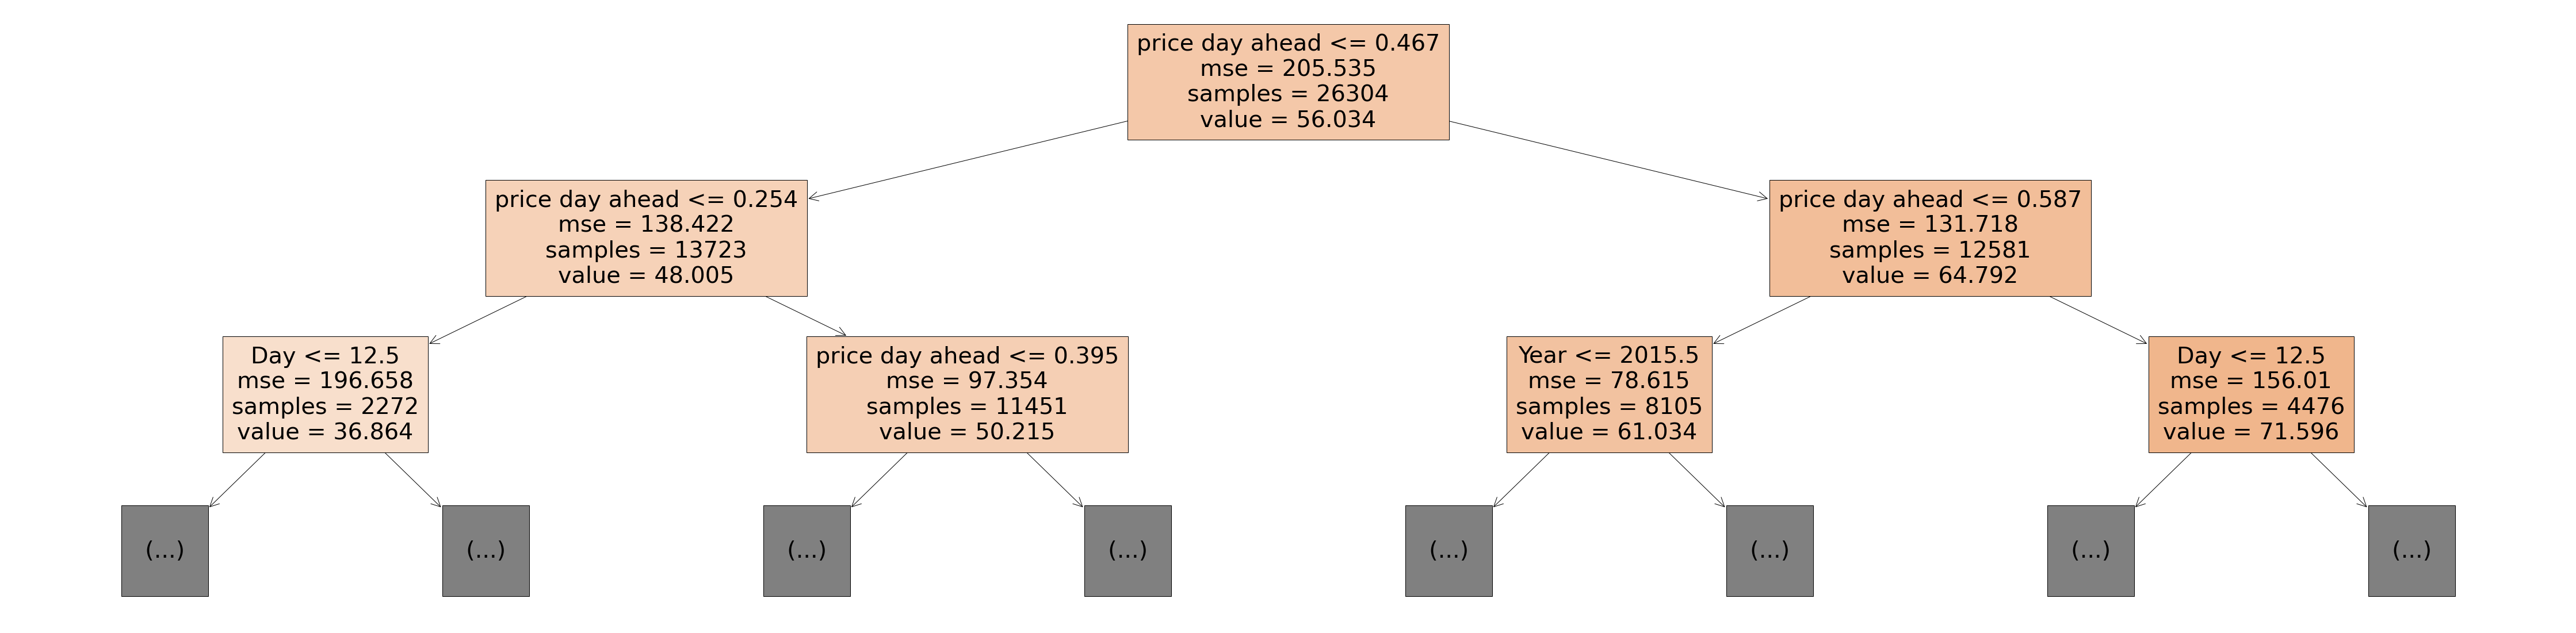

In [81]:
plt.figure(figsize=(80,20))
plot_tree(model, feature_names=X_train.columns, max_depth=2, filled=True);

In [82]:
importance_df = pd.DataFrame({
    'feature': X_train.columns,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)

In [83]:
importance_df.head(10)

,feature,importance
24,price day ahead,0.541099
77,Day,0.129429
78,WeekOfYear,0.055878
76,Year,0.053971
79,Month,0.036669
80,dayofweek,0.022812
0,generation biomass,0.016743
27,temp_max,0.014051
11,generation hydro water reservoir,0.011263
22,total load forecast,0.011037


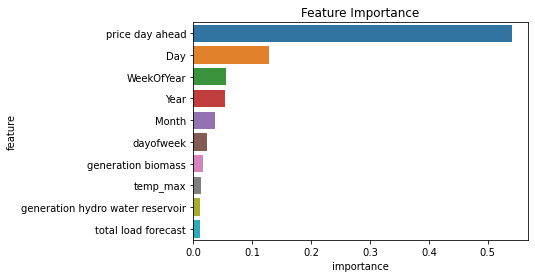

In [84]:
plt.title('Feature Importance')
sns.barplot(data=importance_df.head(10), x='importance', y='feature');

In [85]:
test_preds = model.predict(X_test)

In [86]:
df = pd.DataFrame({'Real Values':test_targets['price actual'], 'Predicted Values':test_preds})
df

,Real Values,Predicted Values
26304,20.76,44.42
26305,19.02,44.42
26306,17.90,44.42
26307,20.88,44.42
26308,18.83,44.42
...,...,...
35059,77.02,74.21
35060,76.16,74.21
35061,74.30,74.72
35062,69.89,74.72


In [87]:
mean_squared_error(test_targets, test_preds, squared=False)

10.868977736814948

In [89]:
#Training the same decision tree regressor with different hyperparameters


In [90]:
model = DecisionTreeRegressor(max_depth=3, random_state=42)

In [91]:
model.fit(X_train, train_targets)

DecisionTreeRegressor(max_depth=3, random_state=42)

In [92]:
model.score(X_train, train_targets)

0.5718987198867294

In [93]:
model.score(X_test, test_targets)

0.40747433364707786

In [94]:
def max_depth_error(md):
    model = DecisionTreeRegressor(max_depth=md, random_state=42)
    model.fit(X_train, train_targets)
    train_acc = 1 - model.score(X_train, train_targets)
    test_acc = 1 - model.score(X_test, test_targets)
    return {'Max Depth': md, 'Training Error': train_acc, 'Test Error': test_acc}

In [95]:
errors_df = pd.DataFrame([max_depth_error(md) for md in range(1, 21)])

In [96]:
errors_df

,Max Depth,Training Error,Test Error
0,1,0.657870,0.758367
1,2,0.535862,0.616905
2,3,0.428101,0.592526
3,4,0.357675,0.624277
4,5,0.294759,0.582226
5,6,0.232137,0.651887
6,7,0.173741,0.723132
7,8,0.128195,0.657564
8,9,0.094600,0.757776
9,10,0.069471,0.816999


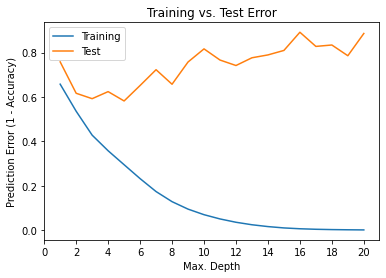

In [97]:
plt.figure()
plt.plot(errors_df['Max Depth'], errors_df['Training Error'])
plt.plot(errors_df['Max Depth'], errors_df['Test Error'])
plt.title('Training vs. Test Error')
plt.xticks(range(0,21, 2))
plt.xlabel('Max. Depth')
plt.ylabel('Prediction Error (1 - Accuracy)')
plt.legend(['Training', 'Test'])

In [98]:
model = DecisionTreeRegressor(max_leaf_nodes=128, random_state=42)

In [99]:
model.fit(X_train, train_targets)

DecisionTreeRegressor(max_leaf_nodes=128, random_state=42)

In [100]:
model.score(X_train, train_targets)

0.8713171194653384

In [101]:
model.score(X_test, test_targets)

0.3611121004519039

# Random forrest

In [103]:
from sklearn.ensemble import RandomForestRegressor

In [104]:
model = RandomForestRegressor(n_jobs=-1, random_state=42)

In [105]:
%%time
model.fit(X_train, train_targets)

Wall time: 11.3 s


RandomForestRegressor(n_jobs=-1, random_state=42)

In [106]:
model.score(X_train, train_targets)

0.9942353641491263

In [107]:
model.score(X_test, test_targets)

0.4327812492356149

In [108]:
X_test

,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage consumption,generation hydro run-of-river and poundage,generation hydro water reservoir,generation marine,generation nuclear,generation other,generation other renewable,generation solar,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main_clear,weather_main_clouds,weather_main_drizzle,weather_main_fog,weather_main_haze,weather_main_mist,weather_main_rain,weather_main_snow,weather_main_thunderstorm,weather_description_broken clouds,weather_description_drizzle,weather_description_few clouds,weather_description_fog,weather_description_haze,weather_description_heavy intensity drizzle,weather_description_heavy intensity rain,weather_description_heavy intensity shower rain,weather_description_light intensity drizzle,weather_description_light intensity drizzle rain,weather_description_light intensity shower rain,weather_description_light rain,weather_description_light rain and snow,weather_description_light snow,weather_description_mist,weather_description_moderate rain,weather_description_overcast clouds,weather_description_proximity shower rain,weather_description_proximity thunderstorm,weather_description_rain and drizzle,weather_description_rain and snow,weather_description_scattered clouds,weather_description_shower rain,weather_description_sky is clear,weather_description_sleet,weather_description_snow,weather_description_thunderstorm,weather_description_thunderstorm with heavy rain,weather_description_thunderstorm with light rain,weather_description_thunderstorm with rain,Year,Day,WeekOfYear,Month,dayofweek
26304,0.476351,0.0,0.0,0.173255,0.119153,0.432071,0.0,0.0,0.0,0.462967,0.5380,0.119449,0.0,0.991569,0.490566,0.663866,0.001554,0.663866,0.0,0.708190,0.001028,0.735299,0.224136,0.206233,0.046833,0.311151,0.291932,0.325094,0.895652,0.88,0.333333,0.777778,0.0,0.0,0.0,0.0,0.993377,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2018,1,1,1,0
26305,0.464527,0.0,0.0,0.163173,0.114727,0.425390,0.0,0.0,0.0,0.467610,0.5230,0.082134,0.0,0.991569,0.481132,0.647059,0.001554,0.666667,0.0,0.639826,0.000000,0.656663,0.196822,0.172717,0.026819,0.313997,0.312758,0.305991,0.895652,0.65,0.222222,0.777778,0.0,0.0,0.0,0.0,0.993377,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2018,1,1,1,0
26306,0.469595,0.0,0.0,0.176750,0.121306,0.425390,0.0,0.0,0.0,0.450365,0.5240,0.092311,0.0,0.991710,0.481132,0.663866,0.001554,0.661064,0.0,0.541237,0.000171,0.611412,0.146704,0.110908,0.016011,0.334323,0.333583,0.325094,0.895652,0.61,0.277778,0.777778,0.0,0.0,0.0,0.0,0.993377,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2018,1,1,1,0
26307,0.469595,0.0,0.0,0.172207,0.124776,0.425390,0.0,0.0,0.0,0.470042,0.5105,0.073396,0.0,0.992132,0.490566,0.663866,0.001554,0.666667,0.0,0.371301,0.000685,0.457046,0.094009,0.065552,0.002402,0.325176,0.312758,0.325094,0.895652,0.89,0.277778,0.777778,0.0,0.0,0.0,0.0,0.993377,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2018,1,1,1,0
26308,0.471284,0.0,0.0,0.165618,0.127168,0.425390,0.0,0.0,0.0,0.570418,0.5165,0.067948,0.0,0.992834,0.481132,0.663866,0.001554,0.669468,0.0,0.362985,0.001028,0.357936

# Xgboost and Light GBM

In [168]:
X_train['WeekOfYear'] = X_train['WeekOfYear'].astype('int32')
X_test['WeekOfYear'] = X_test['WeekOfYear'].astype('int32')


In [159]:
pip install xgboost

In [160]:
from xgboost import XGBRegressor, plot_importance, plot_tree
import lightgbm

In [161]:
model = XGBRegressor(random_state=42, n_jobs=-1, n_estimators=20, max_depth=4)

In [162]:
%%time
model.fit(X_train, train_targets)

Wall time: 410 ms


XGBRegressor(base_score=0.5, booster='gbtree', colsample_bylevel=1,
             colsample_bynode=1, colsample_bytree=1, gamma=0, gpu_id=-1,
             importance_type='gain', interaction_constraints='',
             learning_rate=0.300000012, max_delta_step=0, max_depth=4,
             min_child_weight=1, missing=nan, monotone_constraints='()',
             n_estimators=20, n_jobs=-1, num_parallel_tree=1, random_state=42,
             reg_alpha=0, reg_lambda=1, scale_pos_weight=1, subsample=1,
             tree_method='exact', validate_parameters=1, verbosity=None)

In [163]:
preds = model.predict(X_train)

In [164]:
preds

array([41.840214, 41.62673 , 41.62673 , ..., 39.221638, 30.01689 ,
       30.31719 ], dtype=float32)

In [165]:
mean_squared_error(preds, train_targets, squared=False)

3.876930131211783

In [170]:
test_preds = model.predict(X_test)
mean_squared_error(test_preds, test_targets, squared=False)

9.913511252074736

In [116]:
pip install xdot

In [117]:
import matplotlib.pyplot as plt
from xgboost import plot_tree
from matplotlib.pylab import rcParams
import graphviz
%matplotlib inline

rcParams['figure.figsize'] = 30,30

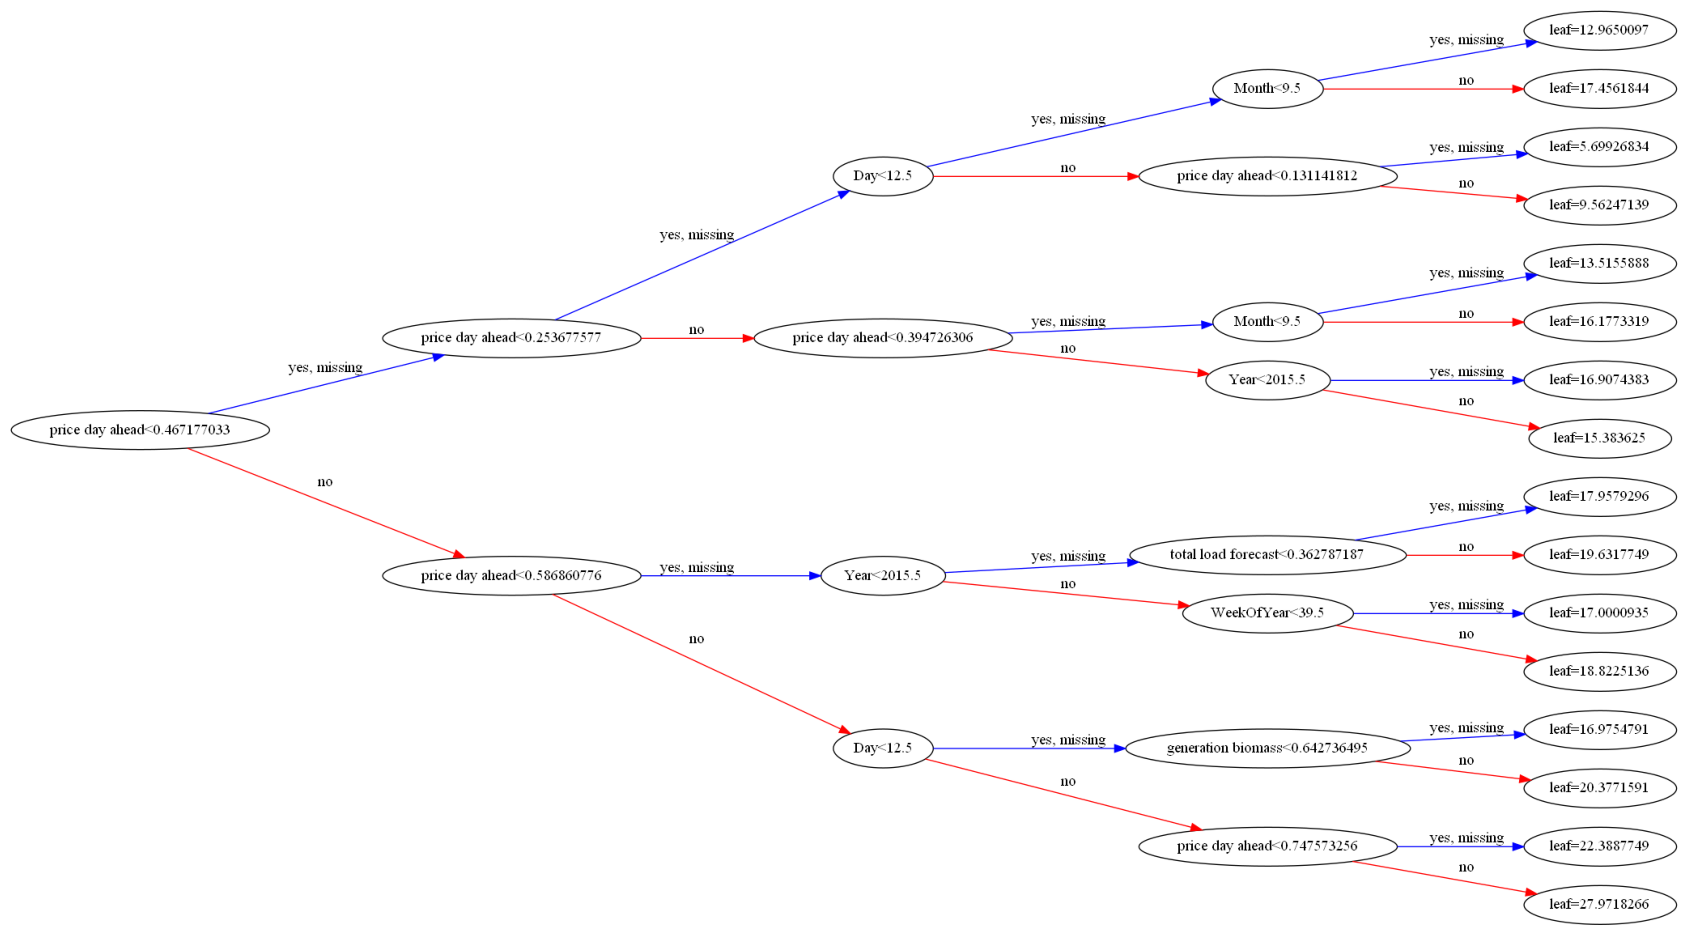

In [120]:
plot_tree(model, rankdir='LR');

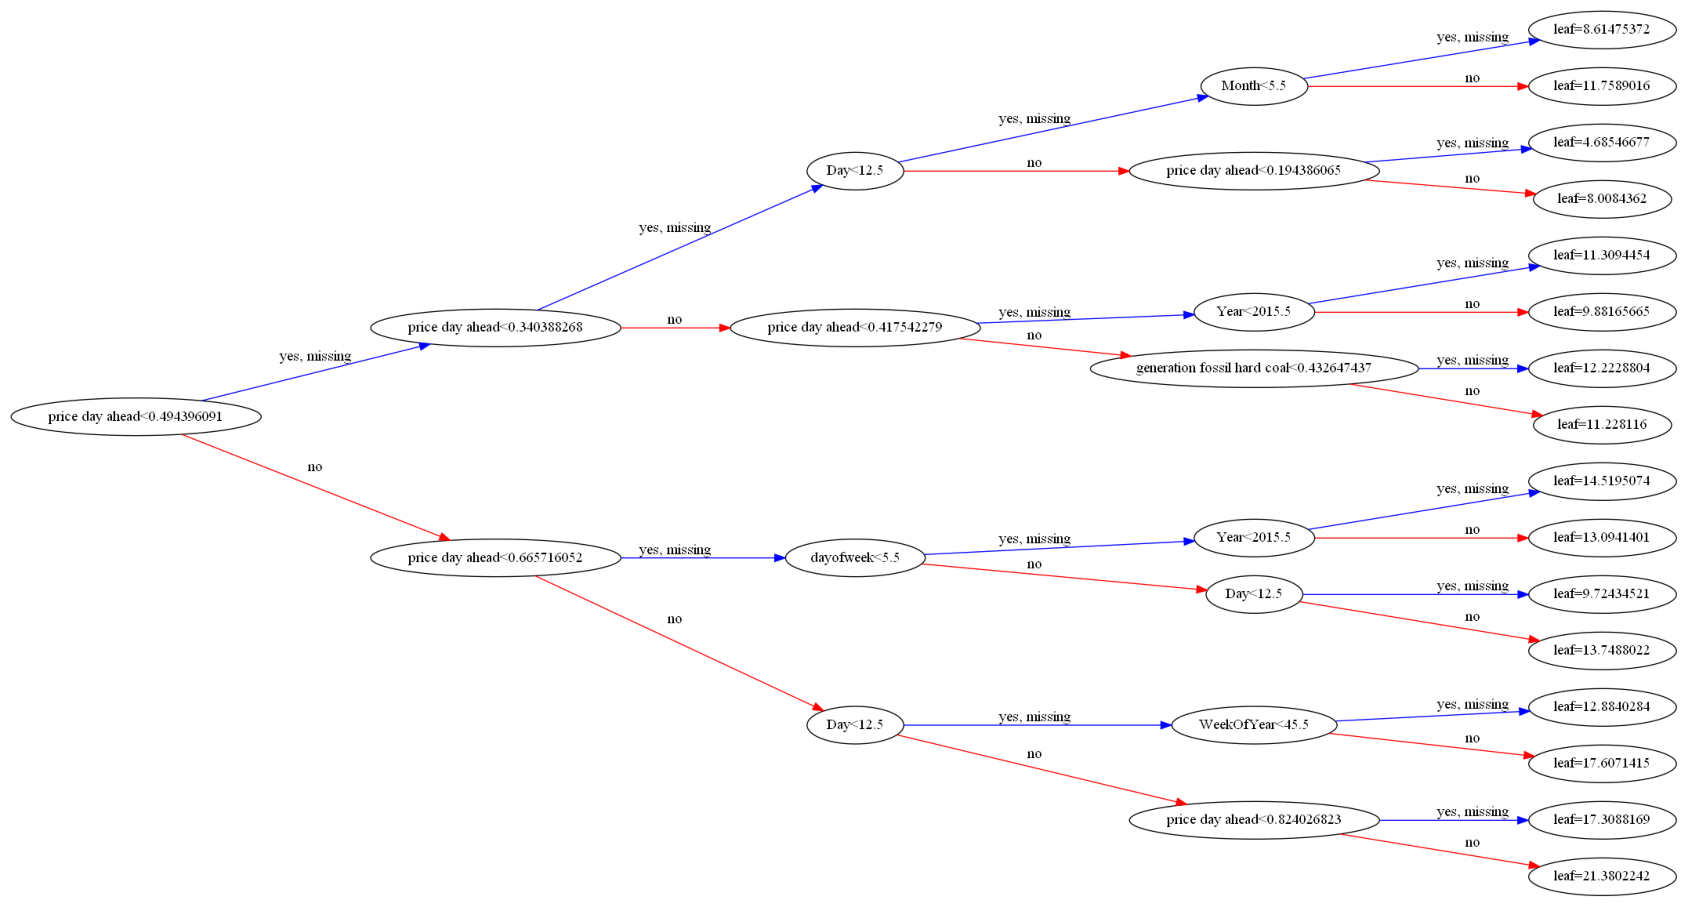

In [121]:
plot_tree(model, rankdir='LR' , num_trees=1);

<AxesSubplot:title={'center':'Feature importance'}, xlabel='F score', ylabel='Features'>

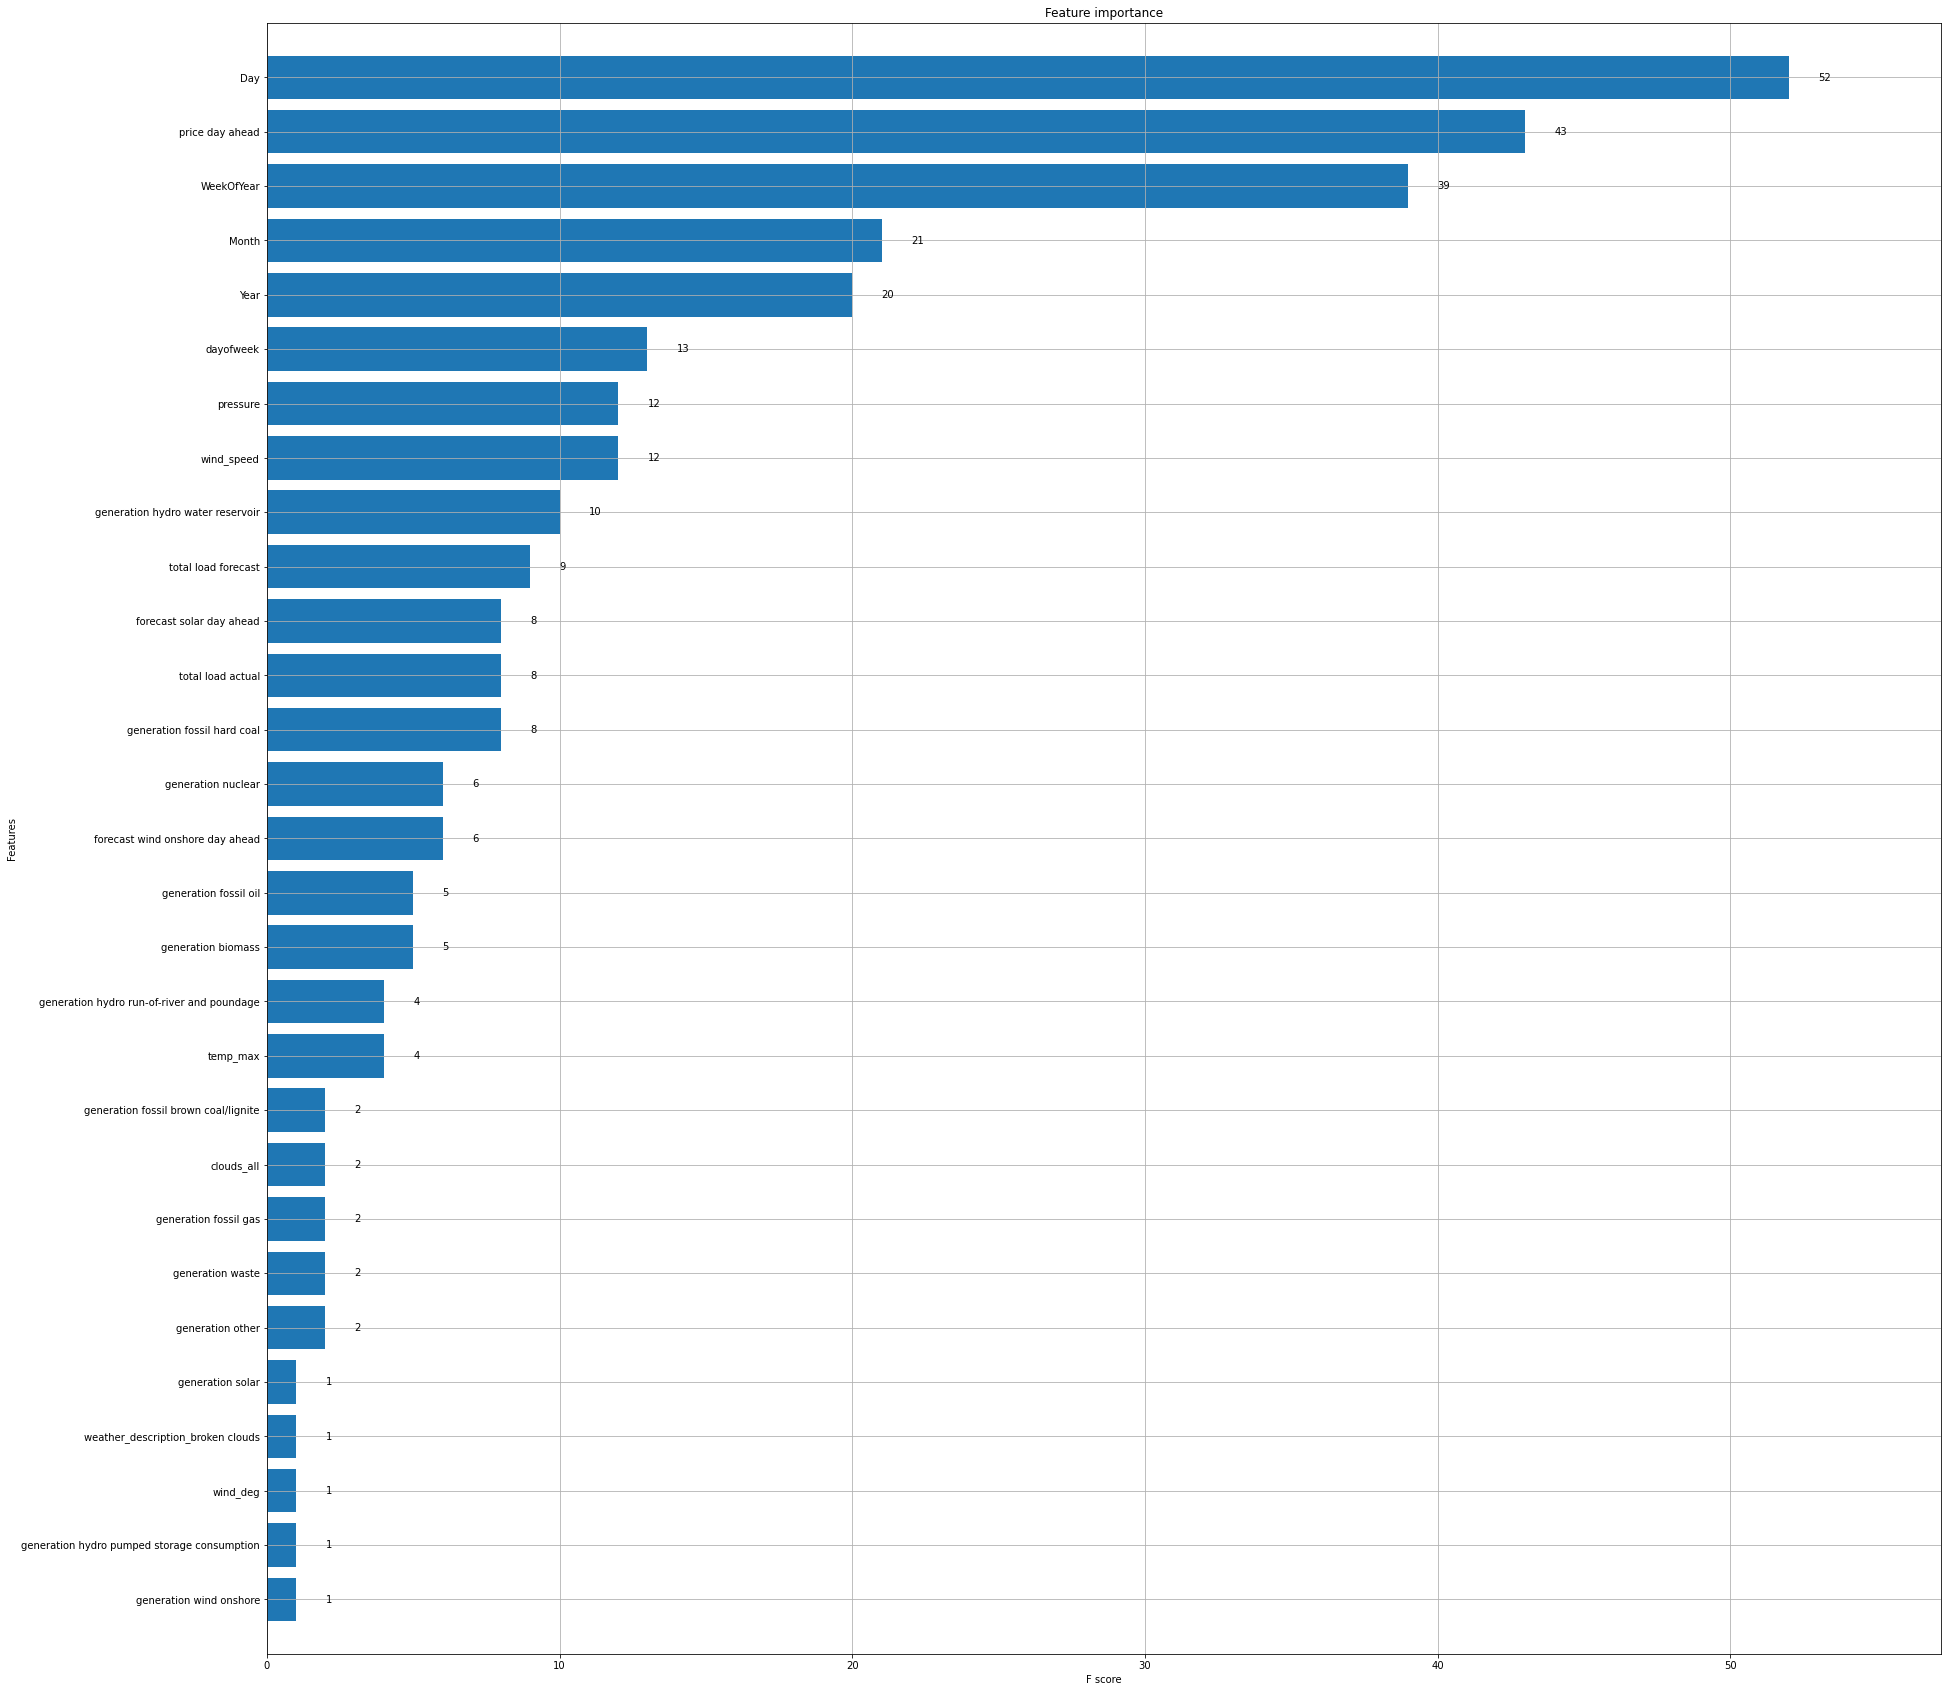

In [127]:
plot_importance(booster=model,
                height=0.8)

In [128]:
importance_df = pd.DataFrame({
    'feature': X_train.columns,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)

In [129]:
importance_df.head(10)

,feature,importance
24,price day ahead,0.323831
76,Year,0.066003
77,Day,0.063663
79,Month,0.060962
19,generation wind onshore,0.045735
14,generation other,0.042932
80,dayofweek,0.039601
22,total load forecast,0.034707
0,generation biomass,0.033142
78,WeekOfYear,0.033006


In [171]:
from sklearn.metrics import mean_squared_error

def rmse(a, b):
    return mean_squared_error(a, b, squared=False)

In [183]:
model = XGBRegressor(random_state=42, n_jobs=-1, n_estimators=20, max_depth=5)

In [184]:
%%time
model.fit(X_train, train_targets)

Wall time: 418 ms


XGBRegressor(base_score=0.5, booster='gbtree', colsample_bylevel=1,
             colsample_bynode=1, colsample_bytree=1, gamma=0, gpu_id=-1,
             importance_type='gain', interaction_constraints='',
             learning_rate=0.300000012, max_delta_step=0, max_depth=5,
             min_child_weight=1, missing=nan, monotone_constraints='()',
             n_estimators=20, n_jobs=-1, num_parallel_tree=1, random_state=42,
             reg_alpha=0, reg_lambda=1, scale_pos_weight=1, subsample=1,
             tree_method='exact', validate_parameters=1, verbosity=None)

In [185]:
preds = model.predict(X_train)

In [186]:
rmse(preds, train_targets)

3.1993672932380366

In [187]:
test_preds = model.predict(X_test)
rmse(test_preds, test_targets)

9.393662954762535

In [195]:
compare_df = pd.DataFrame({"actual": test_targets['price actual'], "prediction_price" : test_preds})

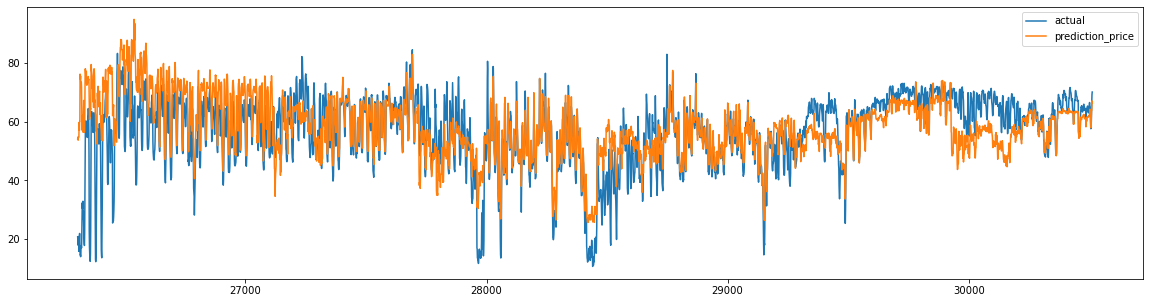

In [196]:
compare_df[["actual","prediction_price"]].plot(figsize=(20,5));


Light GBM


In [197]:
from lightgbm import LGBMRegressor, plot_importance, plot_tree

In [198]:
model = LGBMRegressor(random_state=42)

In [199]:
model.fit(X_train, train_targets)

LGBMRegressor(random_state=42)

In [200]:
train_preds = model.predict(X_train)

In [201]:
rmse(train_preds, train_targets)

2.322617414308489

In [202]:
test_preds = model.predict(X_test)

In [203]:
rmse(test_preds, test_targets)

9.302034256005104

In [205]:
importance_df = pd.DataFrame({
    'feature': X_train.columns,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)

In [207]:
importance_df.head(10)

,feature,importance
77,Day,305
78,WeekOfYear,293
24,price day ahead,238
80,dayofweek,142
4,generation fossil hard coal,117
5,generation fossil oil,117
20,forecast solar day ahead,115
28,pressure,108
10,generation hydro run-of-river and poundage,107
11,generation hydro water reservoir,97


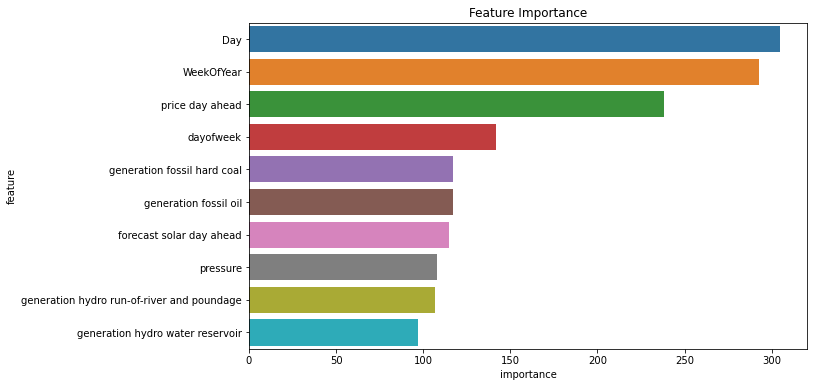

In [208]:
import seaborn as sns
plt.figure(figsize=(10,6))
plt.title('Feature Importance')
sns.barplot(data=importance_df.head(10), x='importance', y='feature');

Modifying the hyperparamaters of Light GBM

In [211]:
import lightgbm

In [220]:
model = LGBMRegressor(n_estimators=10, random_state=42).fit(X_train, train_targets)

In [ ]:
train_preds = model.predict(X_train)
test_preds = model.predict(X_test)

In [221]:
rmse(train_preds, train_targets), rmse(test_preds, test_targets)

(7.004253297212399, 9.781385602781379)

In [222]:
model = LGBMRegressor(n_estimators=100, random_state=42).fit(X_train, train_targets)

In [223]:
train_preds = model.predict(X_train)
test_preds = model.predict(X_test)

In [224]:
rmse(train_preds, train_targets), rmse(test_preds, test_targets)

(2.322617414308489, 9.302034256005104)

Max depth or number of leaves

In [267]:
model = LGBMRegressor(max_depth=8, random_state=42, learning_rate=0.1).fit(X_train, train_targets)

In [265]:
train_preds = model.predict(X_train)
test_preds = model.predict(X_test)

In [266]:
rmse(train_preds, train_targets), rmse(test_preds, test_targets)

(5.638220559289691, 9.530564471278906)

In [277]:
model = LGBMRegressor(boosting_type='gbdt', random_state=42, max_depth=8).fit(X_train, train_targets)

In [278]:
train_preds = model.predict(X_train)
test_preds = model.predict(X_test)

In [279]:
rmse(train_preds, train_targets), rmse(test_preds, test_targets)

(2.403561297082526, 9.139572399056481)

In [283]:
model = LGBMRegressor(num_leaves=128, random_state=42, max_depth=8).fit(X_train, train_targets)

In [284]:
train_preds = model.predict(X_train)
test_preds = model.predict(X_test)

In [285]:
rmse(train_preds, train_targets), rmse(test_preds, test_targets)

(1.5576660331966632, 9.489422550124692)

Best training model with hyper parameters
model = LGBMRegressor(num_leaves=128, random_state=42, max_depth=8).fit(X_train, train_targets)

Best train-test model with hyper parameters
model = LGBMRegressor(boosting_type='gbdt', random_state=42, max_depth=8).fit(X_train, train_targets)

In [287]:
#Show sample predictions

In [308]:
sample_df = pd.read_csv("energy-consumption-generation-prices-and-weather/sample_input.csv")

In [309]:
sample_df

,time,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage aggregated,generation hydro pumped storage consumption,generation hydro run-of-river and poundage,generation hydro water reservoir,generation marine,generation nuclear,generation other,generation other renewable,generation solar,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind offshore eday ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main,weather_description,weather_icon
0,2015-01-05 02:00:00+01:00,359,0,0,4791,2580,311,0,0,0,NaN,1021,1076,2140,0,4028,38,75,662,156,0,7887,566,NaN,7731,22590,21988,35.2,271.258,271.258,271.258,970,67,1,24,0,0,0,0,800,clear,sky is clear,01n


In [310]:
sample_df.drop(['generation hydro pumped storage aggregated', 'forecast wind offshore eday ahead'],axis = 1, inplace=True)

In [311]:
#Time columns modification functions
sample_df.rename(columns={'time' : 'datetime'}, inplace=True)

sample_df[['time', 'timezone']] = sample_df['datetime'].str.split("+", expand=True)
sample_df[['date', 'time_hours']] = sample_df['time'].str.split(" ", expand=True)
split_date(sample_df)
del sample_df['datetime']

In [312]:
sample_df[numeric_cols] = scaler.transform(sample_df[numeric_cols])
sample_df[encoded_cols] = encoder.transform(sample_df[categorical_cols[-2:]])
sample_df = sample_df[numeric_cols + encoded_cols + categorical_cols[:-2]]


In [ ]:
sample_df['WeekOfYear'] = sample_df['WeekOfYear'].astype('int32')

In [316]:
model.predict(sample_df)

array([45.41434011])

In [317]:
print("Actual: 60.91 - prediction 45.41")

Actual: 60.91 - prediction 45.41


In [327]:
sample_2_df = pd.read_csv("energy-consumption-generation-prices-and-weather/sample_2.csv")

In [328]:
sample_2_df

,time,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage aggregated,generation hydro pumped storage consumption,generation hydro run-of-river and poundage,generation hydro water reservoir,generation marine,generation nuclear,generation other,generation other renewable,generation solar,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind offshore eday ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main,weather_description,weather_icon
0,2015-01-05 02:00:00+01:00,359,0,0,4791,2580,311,0,0,0,NaN,1021,1076,2140,0,4028,38,75,662,156,0,7887,566,NaN,7731,22590,21988,35.2,289.55,289.55,289.55,1026,64,1,157,0,0,0,12,801,clouds,few clouds,02d


In [329]:
sample_2_df.drop(['generation hydro pumped storage aggregated', 'forecast wind offshore eday ahead'],axis = 1, inplace=True)
#Time columns modification functions
sample_2_df.rename(columns={'time' : 'datetime'}, inplace=True)

sample_2_df[['time', 'timezone']] = sample_2_df['datetime'].str.split("+", expand=True)
sample_2_df[['date', 'time_hours']] = sample_2_df['time'].str.split(" ", expand=True)
split_date(sample_2_df)
del sample_2_df['datetime']

sample_2_df[numeric_cols] = scaler.transform(sample_2_df[numeric_cols])
sample_2_df[encoded_cols] = encoder.transform(sample_2_df[categorical_cols[-2:]])
sample_2_df = sample_2_df[numeric_cols + encoded_cols + categorical_cols[:-2]]


In [330]:
sample_2_df['WeekOfYear'] = sample_2_df['WeekOfYear'].astype('int32')

In [331]:
model.predict(sample_2_df)

array([46.51662526])

# Saving the trained models

In [333]:
import joblib

In [336]:
energy_price = {
    'model': model,
    'imputer': imputer,
    'scaler': scaler,
    'encoder': encoder,
    'input_cols': input_cols,
    'target_col': target_cols,
    'numeric_cols': numeric_cols,
    'categorical_cols': categorical_cols,
    'encoded_cols': encoded_cols
}

In [337]:
joblib.dump(energy_price, 'energy_price.joblib')

['energy_price.joblib']

In [338]:
energy_model = joblib.load('energy_price.joblib')

# Summary and references

The following Kaggle dataset was used in this notebook:
https://www.kaggle.com/nicholasjhana/energy-consumption-generation-prices-and-weather

The data consists of 29 columns in energy dataset, and 17 columns in weather dataset
It also has 35k tuples in energy dataset plus 178k tuples in weather dataset
We have trained the model on Madrid weather and corresponding hourly energy generations. variables like price day ahead and what day of the month it is, day of week, had huge feature importances. Weather conditions affect the prices a lot too.

I have trained a decision tree regressor, Gradient boosting model and Light GBM model in this notebook. I have also done some regularization and hyperparameter tuning to reduce overfitting and imporve test accuracy.

The best model was Light GBM with boosting_type='gbdt' and max_depth of 8 low training time, overall accuracy of (2.403561297082526, 9.139572399056481) for train and test respectively for corresponding prices.


